# Tarea 1 · Parte 1: de El Comercio a un CSV limpio
Pregunta guía: **¿Se pueden convertir titulares peruanos en un clasificador de noticias?**  
Antes de meter modelos o transformers, lo primero es tener datos confiables y bien estructurados. Este notebook cubre la recolección, limpieza y una primera mirada exploratoria (EDA). Para este trabajo se elegió la **Opción B (El Comercio)**.
**Decisiones de diseño y extracción:**
* **Fecha:** 18 de octubre de 2026.
* **Fuente:** Revisé el `robots.txt` de El Comercio (`https://elcomercio.pe/robots.txt`). No prohíbe las páginas de noticias (solo `/catalogo/`, `/buscar/` y archivos antiguos) y publica sitemaps limpios por sección (`/sitemap/web/politica/`, `/economia/`, `/deporte-total/`, `/tecnologia/`). Parto de ahí en vez de raspar el HTML de portada, que cambia todo el tiempo y puede introducir ruido.
* **Cortesía:** User-Agent con identificación académica, pausas de cortesía entre peticiones y reintentos controlados para no saturar el servidor del diario.
* **Respaldo crudo:** Todo lo descargado se guarda en `datos/raw/elcomercio_raw.json` y los descartes en `datos/raw/descartes.json`. Si el notebook se reinicia, no hace falta volver a descargar nada de la web.
* **Etiqueta provisional:** En esta primera parte la categoría sale de la sección del sitemap donde estaba la URL (mapeada a las 4 oficiales: `politica`, `economia`, `deportes`, `ciencia_tecnologia`). En la Parte 2 la contrasto con el LLM y la auditoría manual.

In [1]:
import json
import re
import time
import urllib.robotparser
from collections import Counter
from pathlib import Path
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup

sns.set_theme(style="whitegrid", context="notebook")

RAW = Path("datos/raw")
RAW.mkdir(parents=True, exist_ok=True)

HEADERS = {"User-Agent": "tarea1-ds-python-up/1.0 (trabajo academico, Universidad del Pacifico; fampuero@poverty-action.org)"}
PAUSA = 1.5          # segundos entre pedidos
BASE = "https://elcomercio.pe"

## 1. ¿Me dejan entrar?

En vez de confiar en mi lectura del `robots.txt`, se pregunta a `urllib.robotparser` con mi propio User-Agent
y con las rutas que voy a pedir.

In [2]:
rp = urllib.robotparser.RobotFileParser(f"{BASE}/robots.txt")
rp.set_url(f"{BASE}/robots.txt")
rp.read()

pruebas = [
    "/sitemap/web/politica/?outputType=xml",
    "/politica/gobierno/un-articulo-cualquiera-noticia/",
    "/deporte-total/futbol-peruano/otro-articulo-noticia/",
    "/buscar/?query=congreso",
]
for ruta in pruebas:
    print(f"{'permitido' if rp.can_fetch(HEADERS['User-Agent'], BASE + ruta) else 'BLOQUEADO':<10} {ruta}")

permitido  /sitemap/web/politica/?outputType=xml
permitido  /politica/gobierno/un-articulo-cualquiera-noticia/
permitido  /deporte-total/futbol-peruano/otro-articulo-noticia/
BLOQUEADO  /buscar/?query=congreso


Las rutas de artículos y sitemaps quedan permitidas; `/buscar/` no, y por eso no la uso.

## 2. Candidatas desde los sitemaps

Cada sección tiene un sitemap con las 100 URLs más recientes. Con cuatro secciones salen 400 candidatas. El volumen que pide la tarea (350–400), antes de descartar lo que no sirva.

In [3]:
SECCIONES = {                      # etiqueta oficial -> sección del sitemap
    "politica": "politica",
    "economia": "economia",
    "deportes": "deporte-total",
    "ciencia_tecnologia": "tecnologia",
}

def pedir(url, reintentos=1):
    """GET cortés: pausa fija y como máximo un reintento."""
    for intento in range(reintentos + 1):
        time.sleep(PAUSA)
        try:
            r = requests.get(url, headers=HEADERS, timeout=30)
            if r.status_code == 200:
                return r
            print(f"  HTTP {r.status_code} en {url}")
        except requests.RequestException as e:
            print(f"  error de red ({type(e).__name__}) en {url}")
    return None

candidatas = []
for etiqueta, seccion in SECCIONES.items():
    r = pedir(f"{BASE}/sitemap/web/{seccion}/?outputType=xml")
    sopa = BeautifulSoup(r.text, "xml")
    for u in sopa.find_all("url"):
        candidatas.append({"url": u.loc.text.strip(), "lastmod": u.lastmod.text.strip(),
                           "etiqueta_sitemap": etiqueta})

cand = pd.DataFrame(candidatas)
print(cand.shape)
cand.etiqueta_sitemap.value_counts()

(400, 3)


etiqueta_sitemap
politica              100
economia              100
deportes              100
ciencia_tecnologia    100
Name: count, dtype: int64

## 3. Descarga de los artículos

De cada página saco tres cosas de los metadatos Open Graph, que son más estables que las clases CSS del diseño:
`og:title` (titular), `og:description` (bajada) y `article:published_time` (fecha). Se guarda todo en
`datos/raw/elcomercio_raw.json` a medida que avanzo.

In [4]:
RAW_JSON = RAW / "elcomercio_raw.json"
cache = {r["url"]: r for r in json.loads(RAW_JSON.read_text(encoding="utf-8")) if "tipo_og" in r} if RAW_JSON.exists() else {}

def meta(sopa, clave):
    tag = sopa.find("meta", attrs={"property": clave}) or sopa.find("meta", attrs={"name": clave})
    return tag["content"].strip() if tag and tag.get("content") else ""

def extraer(url, html):
    sopa = BeautifulSoup(html, "lxml")
    h1 = sopa.find("h1")
    return {
        "url": url,
        "titular": meta(sopa, "og:title") or (h1.get_text(strip=True) if h1 else ""),
        "bajada": meta(sopa, "og:description"),
        "fecha": meta(sopa, "article:published_time")[:10],
        "tipo_og": meta(sopa, "og:type"),
    }

pendientes = [u for u in cand.url if u not in cache]
print(f"{len(cache)} ya en caché, {len(pendientes)} por descargar (~{len(pendientes) * PAUSA / 60:.0f} min)")

fallos = []
for i, url in enumerate(pendientes, 1):
    r = pedir(url)
    if r is None:
        fallos.append(url)
        continue
    cache[url] = extraer(url, r.text)
    if i % 25 == 0:
        RAW_JSON.write_text(json.dumps(list(cache.values()), ensure_ascii=False, indent=1), encoding="utf-8")
        print(f"  {i}/{len(pendientes)}")

RAW_JSON.write_text(json.dumps(list(cache.values()), ensure_ascii=False, indent=1), encoding="utf-8")
print(f"Descargadas: {len(cache)} · fallos tras reintento: {len(fallos)}")

399 ya en caché, 2 por descargar (~0 min)


Descargadas: 401 · fallos tras reintento: 0


## 4. Limpieza y descartes

La tarea pide no esconder lo que se descarta):

1. Sin titular o sin bajada utilizable (menos de 30 caracteres) → se descarta.
2. URL repetida entre sitemaps → se queda una.
3. **La URL debe empezar por la sección esperada.** Los sitemaps de El Comercio arrastran notas de otras
   secciones (opinión, `ecdata`, `ruedas-tuercas`, BBC Mundo…). Si una nota de `tecnologia` vive en
   `/ruedas-tuercas/`, no es claramente ciencia y tecnología: no invento una quinta categoría, la descarto.

In [5]:
df = cand.merge(pd.DataFrame(cache.values()), on="url", how="left")
df["segmento"] = df.url.map(lambda u: urlparse(u).path.strip("/").split("/")[0])
df["subseccion"] = df.url.map(lambda u: (lambda seg: seg[1] if len(seg) >= 3 else "")(urlparse(u).path.strip("/").split("/")))

esperado = {et: sec for et, sec in SECCIONES.items()}
descartes = []

def descartar(mask, motivo):
    global df
    for _, f in df[mask].iterrows():
        descartes.append({"url": f.url, "etiqueta_sitemap": f.etiqueta_sitemap,
                          "seccion_url": f.segmento, "motivo": motivo})
    df = df[~mask]

descartar(df.titular.isna() | (df.titular.fillna("").str.len() == 0), "sin titular (no se pudo descargar)")
descartar(df.bajada.fillna("").str.len() < 30, "bajada ausente o demasiado corta")
descartar(df.url.duplicated(keep="first"), "URL repetida entre sitemaps")
descartar(df.titular.duplicated(keep="first"), "titular repetido")
descartar(df.segmento != df.etiqueta_sitemap.map(esperado), "la nota vive en otra sección del diario")

desc = pd.DataFrame(descartes)
(RAW / "descartes.json").write_text(desc.to_json(orient="records", force_ascii=False, indent=1), encoding="utf-8")
print(f"Quedan {len(df)} de {len(cand)}. Descartadas: {len(desc)}")
display(desc.groupby(["motivo", "seccion_url"]).size().rename("n").reset_index())

Quedan 382 de 400. Descartadas: 18


,motivo,seccion_url,n
0,URL repetida entre sitemaps,tecnologia,1
1,bajada ausente o demasiado corta,ecdata,1
2,la nota vive en otra sección del diario,bbc-news-mundo,2
3,la nota vive en otra sección del diario,ecdata,3
4,la nota vive en otra sección del diario,eldominical,1
5,la nota vive en otra sección del diario,elecciones,1
6,la nota vive en otra sección del diario,opinion,6
7,la nota vive en otra sección del diario,ruedas-tuercas,2
8,la nota vive en otra sección del diario,tecnologia,1


## 5. Esquema final y control de calidad

`seccion_original` es la subsección tal como aparece en la URL del diario (`futbol-peruano`, `inteligencia-artificial`…).

In [6]:
final = pd.DataFrame({
    "titular": df.titular.str.strip(),
    "bajada": df.bajada.str.strip(),
    "medio": "El Comercio",
    "seccion_original": df.subseccion.where(df.subseccion != "", df.segmento),
    "url": df.url,
    "fecha": df.fecha,
    "etiqueta": df.etiqueta_sitemap,
}).reset_index(drop=True)

assert final.shape[1] == 7 and final.url.is_unique
assert set(final.etiqueta) == set(SECCIONES), "faltan categorías"
assert final.isna().sum().sum() == 0

final.to_csv("datos/noticias.csv", index=False, encoding="utf-8")
print(final.shape)
final.etiqueta.value_counts()

(382, 7)


etiqueta
economia              99
deportes              98
ciencia_tecnologia    94
politica              91
Name: count, dtype: int64

### Tabla de equivalencias: sección del diario → categoría oficial

La etiqueta sale de la sección del sitemap de donde vino la URL. Debajo, cada categoría con las subsecciones
reales que quedaron dentro (`seccion_original`) y cuántas noticias aportó cada una.

In [7]:
equivalencias = (
    final.groupby(["etiqueta", "seccion_original"]).size().rename("noticias").reset_index()
    .assign(seccion_sitemap=lambda t: t.etiqueta.map(SECCIONES))
    .sort_values(["etiqueta", "noticias"], ascending=[True, False])
    [["seccion_sitemap", "etiqueta", "seccion_original", "noticias"]]
)
equivalencias.columns = ["sección del sitemap", "categoría oficial", "subsección (seccion_original)", "noticias"]
print(f"{len(equivalencias)} subsecciones repartidas en 4 categorías")
equivalencias.reset_index(drop=True)

35 subsecciones repartidas en 4 categorías


,sección del sitemap,categoría oficial,subsección (seccion_original),noticias
0,tecnologia,ciencia_tecnologia,actualidad,37
1,tecnologia,ciencia_tecnologia,inteligencia-artificial,19
2,tecnologia,ciencia_tecnologia,ciencias,9
3,tecnologia,ciencia_tecnologia,ciberseguridad,7
4,tecnologia,ciencia_tecnologia,ecologia,6
5,tecnologia,ciencia_tecnologia,videojuegos,5
6,tecnologia,ciencia_tecnologia,moviles,4
7,tecnologia,ciencia_tecnologia,gadgets,3
8,tecnologia,ciencia_tecnologia,redes-sociales,2
9,tecnologia,ciencia_tecnologia,robotica,1


### ¿Las URLs siguen vivas?

La tarea exige enlaces funcionales. Se comprueba una muestra de 30 con `HEAD` (más liviano que `GET`).

In [8]:
muestra = final.sample(30, random_state=0)
estados = []
for u in muestra.url:
    time.sleep(PAUSA)
    try:
        estados.append(requests.head(u, headers=HEADERS, timeout=30, allow_redirects=True).status_code)
    except requests.RequestException:
        estados.append(None)
print(Counter(estados))

Counter({200: 30})


## 6. Primera mirada a los datos

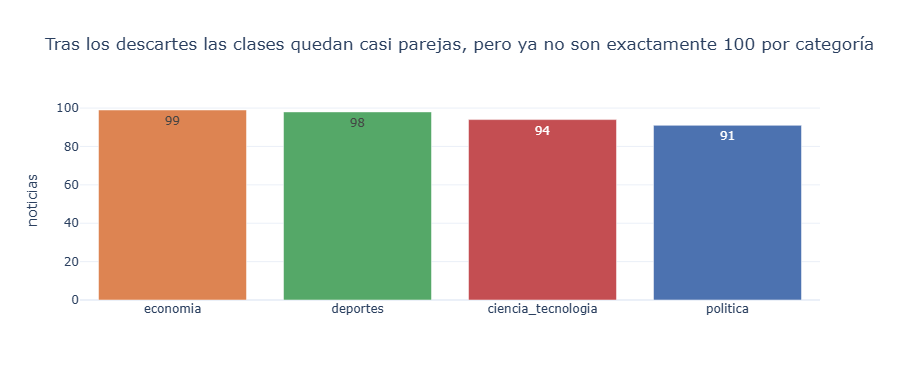

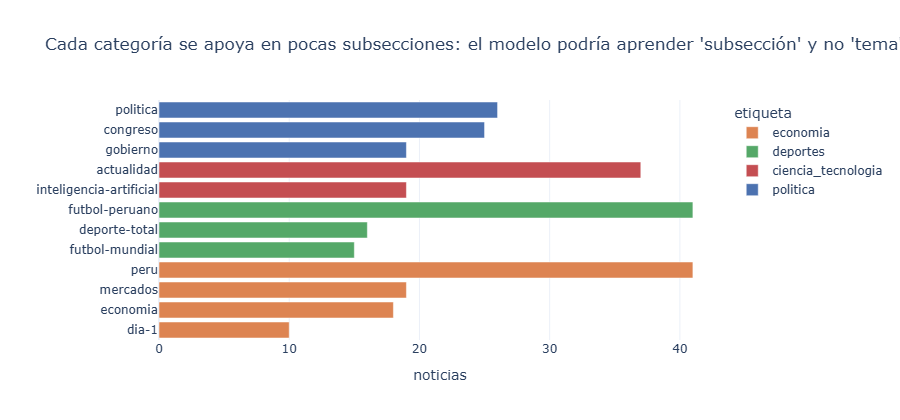

In [9]:
import plotly.express as px
import plotly.io as pio

# Imagen estática: así los gráficos se ven también en GitHub, que no ejecuta el JavaScript de Plotly
pio.renderers.default = "png"
COLORES = {"politica": "#4C72B0", "economia": "#DD8452", "deportes": "#55A868", "ciencia_tecnologia": "#C44E52"}

conteo = final.etiqueta.value_counts().rename_axis("etiqueta").reset_index(name="noticias")
fig1 = px.bar(conteo, x="etiqueta", y="noticias", color="etiqueta", text="noticias", color_discrete_map=COLORES,
              title="Tras los descartes las clases quedan casi parejas, pero ya no son exactamente 100 por categoría")
fig1.update_layout(showlegend=False, xaxis_title="", height=380, template="plotly_white")
fig1.show(width=900, height=380)

sub = final.groupby(["etiqueta", "seccion_original"]).size().rename("noticias").reset_index()
top = sub.sort_values("noticias").tail(12)
fig1b = px.bar(top, y="seccion_original", x="noticias", color="etiqueta", orientation="h", color_discrete_map=COLORES,
               title="Cada categoría se apoya en pocas subsecciones: el modelo podría aprender 'subsección' y no 'tema'")
fig1b.update_layout(yaxis_title="", height=420, template="plotly_white")
fig1b.show(width=900, height=420)

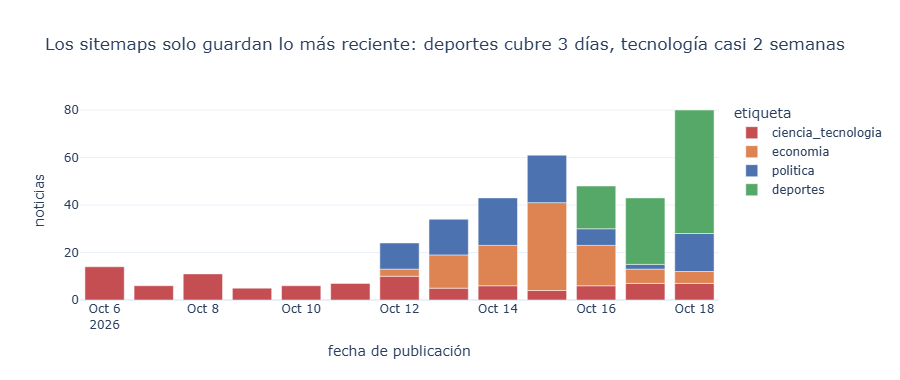

In [10]:
final["fecha_dt"] = pd.to_datetime(final.fecha)
por_dia = final.groupby(["fecha_dt", "etiqueta"]).size().rename("noticias").reset_index()

fig2 = px.bar(por_dia, x="fecha_dt", y="noticias", color="etiqueta", color_discrete_map=COLORES,
              title="Los sitemaps solo guardan lo más reciente: deportes cubre 3 días, tecnología casi 2 semanas")
fig2.update_layout(xaxis_title="fecha de publicación", height=380, template="plotly_white")
fig2.show(width=900, height=380)

▎ Un problema de este dataset es que cada categoría cubre una ventana de tiempo distinta. Deportes concentra sus 98 notas en tres días (16 al 18 de octubre) porque el sitemap solo guarda las 100 URLs más recientes y el fútbol las ocupa rápido. Política y economía abarcan una semana, y tecnología llega hasta el 6 de octubre. El modelo podría estar aprendiendo nombres propios de esta semana y no vocabulario del tema, lo que inflaría las métricas de la Parte 2.


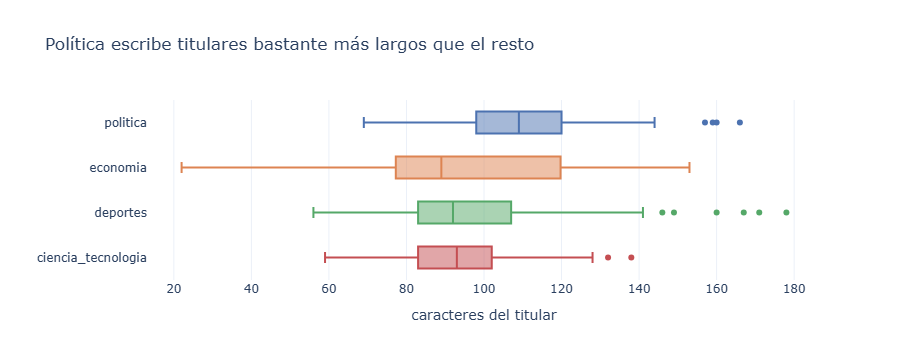

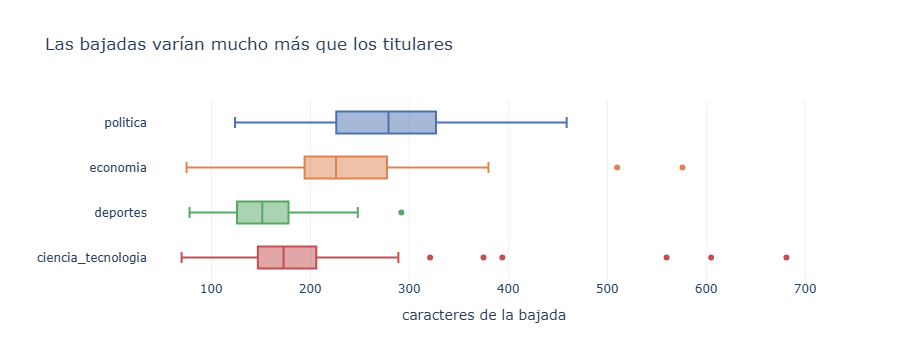

,n_car_titular,n_car_bajada
etiqueta,,
ciencia_tecnologia,93.0,173.0
deportes,92.0,151.5
economia,89.0,226.0
politica,109.0,279.0


In [11]:
final["n_car_titular"] = final.titular.str.len()
final["n_car_bajada"] = final.bajada.str.len()

fig3 = px.box(final, x="n_car_titular", y="etiqueta", color="etiqueta", color_discrete_map=COLORES, points="outliers",
              title="Política escribe titulares bastante más largos que el resto")
fig3.update_layout(showlegend=False, xaxis_title="caracteres del titular", yaxis_title="", height=360, template="plotly_white")
fig3.show(width=900, height=360)

fig3b = px.box(final, x="n_car_bajada", y="etiqueta", color="etiqueta", color_discrete_map=COLORES, points="outliers",
               title="Las bajadas varían mucho más que los titulares")
fig3b.update_layout(showlegend=False, xaxis_title="caracteres de la bajada", yaxis_title="", height=360, template="plotly_white")
fig3b.show(width=900, height=360)

final.groupby("etiqueta")[["n_car_titular", "n_car_bajada"]].median()

Revisar los datos antes de modelar. Tres titulares al azar por categoría:

In [12]:
for et, g in final.groupby("etiqueta"):
    print(f"\n[{et}]")
    for _, f in g.sample(3, random_state=7).iterrows():
        print(f"  · ({f.seccion_original}) {f.titular}")


[ciencia_tecnologia]
  · (moviles) Ventas de ‘smartphones’ registran una caída del 20%, motivado por la crisis de memoria RAM
  · (ciberseguridad) Organización que gestiona Wikipedia denuncia actividad no autorizada de agentes de OpenAI
  · (actualidad) “Ace Combat 8: Wings of Theve” eleva la franquicia a alturas insospechadas | Reseña

[deportes]
  · (futbol-peruano) Mosquera tras vencer a Comerciantes Unidos y seguir en la punta del Clausura: “No solo se ha ganado con talento, sino con personalidad”
  · (futbol-mundial) Bayern Múnich vs. Leipzig (6-1): resumen y goles del partido por la Bundesliga | VIDEO
  · (futbol-mundial) ‘Dibu’ Martínez enciende las alarmas: salió en camilla e inmovilizado tras un fuerte choque en la Premier League | VIDEO

[economia]
  · (peru) El dólar abre a la baja en S/3,42 ante debilitamiento de la divisa estadounidense
  · (mercados) Wall Street cierra en rojo por dato de inflación en Estados Unidos y sector tecnológico
  · (peru) El Indecopi eliminó bar

## Qué queda para la Parte 2

- `datos/noticias.csv`: 7 columnas, URLs reales, etiqueta **provisional** por sección.
- `datos/raw/descartes.json`: lo que no entró y por qué.
- Sospechas ya anotadas: etiquetas con ruido (subsecciones como `actualidad` mezclan temas) y ventanas de
  tiempo distintas por categoría. En la Parte 2 las pongo a prueba con un LLM y con una auditoría manual.